In [1]:
!pip install langchain langgraph langchain-tavily

In [2]:
!pip install -U "langchain-openrouter"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.6/90.6 kB 819.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 837.3/837.3 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 463.6/463.6 kB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 17.3 MB/s eta 0:00:00
  Attempting uninstall: pydantic-core
    Found existing installation: pydantic_core 2.46.5
    Uninstalling pydantic_core-2.46.5:
      Successfully uninstalled pydantic_core-2.46.5
  Attempting uninstall: pydantic
    Found existing installation: pydantic 2.13.5
    Uninstalling pydantic-2.13.5:
      Successfully uninstalled pydantic-2.13.5


In [3]:
import os

os.environ["OPENROUTER_API_KEY"] = "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"
os.environ['TAVILY_API_KEY'] = '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'

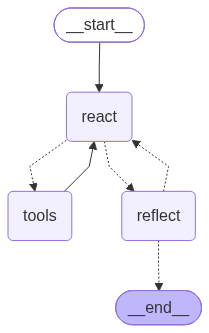


REFLECTION
Decision: stop
Feedback: The answer is comprehensive and well-researched. It properly recommends PostgreSQL with Async support for production AI agents, provides detailed trade-off analysis across all backends (PostgreSQL, SQLite, Redis, In-Memory), includes concrete implementation code, and gives production architecture guidance. The research findings (including security vulnerabilities affecting Redis checkpointer) are accurately reflected. While minor additions could be made (e.g., more explicit mention of the CVE-2026-27022 security issue), the core recommendation and analysis are solid and directly address the user's request. The answer is clear, actionable, and useful for someone looking to implement production-ready LangGraph persistence.

FINAL ANSWER:
Based on extensive research, I'll provide a comprehensive analysis of LangGraph persistence options for production AI agents, along with my recommendation.

## Available Persistence Backends

LangGraph offers several 

In [6]:
from typing import Annotated, Literal
from typing_extensions import TypedDict

from pydantic import BaseModel

from langchain_openrouter import ChatOpenRouter
from langchain_tavily import TavilySearch

from langchain_core.messages import HumanMessage

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode

from IPython.display import Image, display


# ============================================================
# 1. STATE
# ============================================================

class State(TypedDict):
    messages: Annotated[list, add_messages]
    decision: str


# ============================================================
# 2. LLM
# ============================================================

llm = ChatOpenRouter(
    model="openrouter/free",
    max_tokens=2048
)


# ============================================================
# 3. TOOLS
# ============================================================

search = TavilySearch(
    max_results=3
)

tools = [
    search
]

llm_with_tools = llm.bind_tools(tools)

tool_node = ToolNode(tools)


# ============================================================
# 4. REACT AGENT
# ============================================================

def react(state: State):

    response = llm_with_tools.invoke(
        state["messages"]
    )

    return {
        "messages": [response]
    }


# ============================================================
# 5. REACT ROUTER
# ============================================================

def react_router(state: State):

    last_message = state["messages"][-1]

    if last_message.tool_calls:
        return "tools"

    return "reflect"


# ============================================================
# 6. REFLECTION OUTPUT
# ============================================================

class ReflectionDecision(BaseModel):

    decision: Literal["continue", "stop"]

    feedback: str


reflector = llm.with_structured_output(
    ReflectionDecision
)


# ============================================================
# 7. REFLECTOR
# ============================================================

def reflect(state: State):

    response = reflector.invoke([
        *state["messages"],

        HumanMessage(
            content="""
            Review the answer produced by the ReAct agent.

            Check:

            1. Did it answer the user's question?
            2. Is the information supported by the research?
            3. Are important points missing?
            4. Is the answer clear and useful?

            Return:

            stop
            → if the answer is good enough.

            continue
            → if the ReAct agent should research or improve
              the answer further.

            Provide specific feedback.
            """
        )
    ])

    print("\nREFLECTION")
    print("Decision:", response.decision)
    print("Feedback:", response.feedback)

    return {
        "decision": response.decision,

        "messages": [

            HumanMessage(
                content=f"""
                Reflection feedback:

                {response.feedback}
                """
            )


        ]
    }


# ============================================================
# 8. REFLECTION ROUTER
# ============================================================

MAX_REFLECTIONS = 3
reflection_count = 0


def reflection_router(state: State):

    global reflection_count

    reflection_count += 1

    # LLM says STOP
    if state["decision"] == "stop":
        return END

    # Safety limit
    if reflection_count >= MAX_REFLECTIONS:
        return END

    # LLM says CONTINUE
    return "react"


# ============================================================
# 9. BUILD GRAPH
# ============================================================

graph = StateGraph(State)


graph.add_node(
    "react",
    react
)

graph.add_node(
    "tools",
    tool_node
)

graph.add_node(
    "reflect",
    reflect
)


# START → REACT

graph.add_edge(
    START,
    "react"
)


# REACT → TOOL / REFLECT

graph.add_conditional_edges(
    "react",
    react_router,
    {
        "tools": "tools",
        "reflect": "reflect"
    }
)


# TOOL → REACT

graph.add_edge(
    "tools",
    "react"
)


# REFLECT → REACT / END

graph.add_conditional_edges(
    "reflect",
    reflection_router,
    {
        "react": "react",
        END: END
    }
)


# ============================================================
# 10. COMPILE
# ============================================================

app = graph.compile()


# ============================================================
# 11. DISPLAY GRAPH
# ============================================================

png = app.get_graph().draw_mermaid_png()

display(Image(png))


# ============================================================
# 12. RUN
# ============================================================

reflection_count = 0

result = app.invoke({
    "messages": [
        HumanMessage(
            content="""
            Research LangGraph persistence options.

            Recommend a suitable option for a production
            AI agent and explain the trade-offs.
            """
        )
    ],

    "decision": ""
})


# ============================================================
# 13. PRINT FINAL ANSWER
# ============================================================

print("\nFINAL ANSWER:")

for message in reversed(result["messages"]):

    if message.type == "ai" and not message.tool_calls:

        print(message.content)

        break

# **Job Recommender Agent**

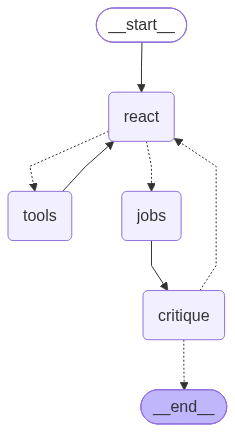

AttributeError: 'NoneType' object has no attribute 'jobs'

In [8]:
from typing import TypedDict, Annotated, Literal

from pydantic import BaseModel

from langchain_core.messages import HumanMessage, SystemMessage
from langchain_openrouter import ChatOpenRouter
from langchain_tavily import TavilySearch

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode

from IPython.display import Image, display


# ============================================================
# STATE
# ============================================================

class State(TypedDict):
    messages: Annotated[list, add_messages]
    jobs: list
    decision: str
    feedback: str


# ============================================================
# LLM
# ============================================================

llm = ChatOpenRouter(
    model="openrouter/free",
    max_tokens=2048
)


# ============================================================
# SEARCH TOOL
# ============================================================

search = TavilySearch(
    max_results=5
)

tools = [search]

llm_with_tools = llm.bind_tools(tools)

tool_node = ToolNode(tools)


# ============================================================
# JOB STRUCTURED OUTPUT
# ============================================================

class Job(BaseModel):
    title: str
    company: str
    summary: str
    keywords: list[str]
    apply_url: str


class Jobs(BaseModel):
    jobs: list[Job]


job_llm = llm.with_structured_output(Jobs)


# ============================================================
# CRITIQUE STRUCTURED OUTPUT
# ============================================================

class Critique(BaseModel):
    decision: Literal["continue", "stop"]
    feedback: str


critique_llm = llm.with_structured_output(Critique)


# ============================================================
# REACT NODE
# ============================================================

def react(state: State):

    response = llm_with_tools.invoke([
        SystemMessage(content=f"""
You are a job research agent.

Find real current job opportunities matching this candidate:

- 2+ years software development
- Python
- JavaScript / TypeScript
- React
- Node.js
- Spring Boot
- LangChain
- LangGraph
- RAG
- LLMs
- Machine Learning
- Deep Learning
- TensorFlow
- Docker
- Kubernetes

Preferred jobs:

- AI Engineer
- GenAI Engineer
- ML Engineer
- LLM Engineer
- AI Agent Engineer

Preferred locations:

- Bengaluru
- Hyderabad
- Remote

Use the search tool to find real jobs.

Do not invent jobs or URLs.

IMPORTANT:

The previous critique was:

{state["feedback"]}

Use this feedback to improve your research.

Search for additional information if necessary.
"""),

        *state["messages"]
    ])

    return {
        "messages": [response]
    }


# ============================================================
# REACT ROUTER
# ============================================================

def react_router(state: State):

    last_message = state["messages"][-1]

    if last_message.tool_calls:
        return "tools"

    return "jobs"


# ============================================================
# CREATE JOB RECOMMENDATIONS
# ============================================================

def create_jobs(state: State):

    response = job_llm.invoke([
        SystemMessage(content="""
Based on the research above, recommend exactly 5 jobs.

For every job provide:

- title
- company
- summary
- keywords
- apply_url

Only use jobs and URLs found during the research.

Do not invent information.

Make the 5 recommendations as relevant as possible
to the candidate.
"""),

        *state["messages"]
    ])

    return {
        "jobs": response.jobs
    }


# ============================================================
# CRITIQUE NODE
# ============================================================

def critique(state: State):

    response = critique_llm.invoke(
        f"""
You are a strict reviewer of a job recommendation system.

Candidate:

- 2+ years software development
- Python
- JavaScript / TypeScript
- React
- Node.js
- Spring Boot
- LangChain
- LangGraph
- RAG
- LLMs
- Machine Learning
- Deep Learning

Preferred:

- AI Engineer
- GenAI Engineer
- ML Engineer
- LLM Engineer
- AI Agent Engineer

Locations:

- Bengaluru
- Hyderabad
- Remote


Here are the recommended jobs:

{state["jobs"]}


Review them.

Check:

1. Are there exactly 5 jobs?
2. Are they relevant to the candidate?
3. Are they related to AI/ML/LLM/Agents?
4. Are they appropriate for 2+ years experience?
5. Does every job have a title?
6. Does every job have a company?
7. Does every job have a summary?
8. Does every job have keywords?
9. Does every job have an application URL?
10. Are there duplicate jobs?
11. Are the application URLs useful?

If the recommendations are good enough:

decision = "stop"

If more research is needed:

decision = "continue"

The feedback should explain exactly what the
research agent should improve or search for.
"""
    )

    return {
        "decision": response.decision,
        "feedback": response.feedback,

        # Put the critique into the conversation so that
        # ReAct can see it during the next iteration.
        "messages": [
            HumanMessage(
                content=f"""
Critique:

Decision: {response.decision}

Feedback:
{response.feedback}
"""
            )
        ]
    }


# ============================================================
# CRITIQUE ROUTER
# ============================================================

def critique_router(state: State):

    if state["decision"] == "continue":
        return "react"

    return END


# ============================================================
# BUILD GRAPH
# ============================================================

graph = StateGraph(State)

graph.add_node("react", react)
graph.add_node("tools", tool_node)
graph.add_node("jobs", create_jobs)
graph.add_node("critique", critique)


# START → REACT
graph.add_edge(
    START,
    "react"
)


# REACT → TOOLS or JOBS
graph.add_conditional_edges(
    "react",
    react_router,
    {
        "tools": "tools",
        "jobs": "jobs"
    }
)


# TOOLS → REACT
graph.add_edge(
    "tools",
    "react"
)


# JOBS → CRITIQUE
graph.add_edge(
    "jobs",
    "critique"
)


# CRITIQUE → REACT or END
graph.add_conditional_edges(
    "critique",
    critique_router,
    {
        "react": "react",
        END: END
    }
)


# ============================================================
# COMPILE
# ============================================================

app = graph.compile()


# ============================================================
# DISPLAY GRAPH
# ============================================================

png = app.get_graph().draw_mermaid_png()

display(
    Image(png)
)


# ============================================================
# RUN
# ============================================================

result = app.invoke({
    "messages": [
        HumanMessage(
            content="""
Find the 5 best current job opportunities for me.

I am looking for:

- AI Engineer
- GenAI Engineer
- Machine Learning Engineer
- LLM Engineer
- AI Agent Engineer

Preferred locations:

- Bengaluru
- Hyderabad
- Remote
"""
        )
    ],

    "jobs": [],

    "decision": "",

    "feedback": ""
})


# ============================================================
# FINAL RESULT
# ============================================================

print("\n")
print("=" * 70)
print("TOP 5 JOB RECOMMENDATIONS")
print("=" * 70)

for i, job in enumerate(result["jobs"], 1):

    print(f"\n{i}. {job.title}")
    print("-" * 70)

    print("Company:", job.company)

    print("\nSummary:")
    print(job.summary)

    print("\nKeywords:")
    print(", ".join(job.keywords))

    print("\nApply URL:")
    print(job.apply_url)


print("\n")
print("=" * 70)
print("FINAL CRITIQUE")
print("=" * 70)

print("Decision:", result["decision"])
print("Feedback:", result["feedback"])